# 03 Text Features

Builds hand-crafted **caption** features for `train_sample`, `validation` and `test`. Image features are built in `04_image_features`, and CLIP embeddings and the image-caption similarity in `05_clip_features`, since they need a GPU and a different workflow.

Text features target the two caption manipulations:
- **text_attribute**: 1–2 sentiment words flipped, often leaving the sentence ungrammatical
- **text_swap**: the whole caption replaced with one from another article about the same person. Mostly undetectable from the text alone, since the swapped caption is real text. Catching it needs the image (`05_clip_features`).

Captions repeat across rows (an image-only fake keeps the original caption), so features are computed once per distinct caption and joined back.

**How features are stored.** Each feature group is saved as its own file, `data/features/<group>_<split>.parquet`, with one row per `row_id`. Modelling notebooks join the groups they need on `row_id`. **To add a feature later:** add a new section that saves a new group file, without re-running or changing the existing groups.

**Leakage rules**
- Every feature here is a fixed function of a single row's caption. Nothing is fitted to the data, so it is safe to compute the same way on all splits.
- Anything that *learns* from data (TF-IDF vocabulary, scaling, feature selection) is **not** done here. It belongs inside the model pipeline, fitted on train only.
- Never use `image` paths, `fake_cls`, `fake_image_box`, `fake_text_pos` or `image_source` as features (since they are labels).

## 0. Setup

In [1]:
import os
import sys
import time
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FEATURES_DIR = PROJECT_ROOT / "data" / "features"
FEATURES_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train_sample", "validation", "test"]
RANDOM_STATE = 4012

sns.set_theme(style="whitegrid")

In [2]:
data = {split: pd.read_parquet(PROCESSED_DIR / f"{split}.parquet") for split in SPLITS}
pd.Series({split: len(df) for split, df in data.items()}, name="rows")

train_sample    49943
validation      22126
test            50705
Name: rows, dtype: int64

In [3]:
def save_features(features, group):
    """Save one feature group per split. `features` must have a row_id column covering every row of each split."""
    for split, df in data.items():
        split_features = df[["row_id"]].merge(features, on="row_id", how="left")
        assert len(split_features) == len(df), f"{group}: row count changed for {split}"
        assert split_features.drop(columns="row_id").notna().all().all(), f"{group}: missing values for {split}"
        path = FEATURES_DIR / f"{group}_{split}.parquet"
        split_features.to_parquet(path, index=False)
        print(f"{path.relative_to(PROJECT_ROOT)}  {split_features.shape}")


def univariate_auc(features, target, label_df=None):
    """ROC-AUC of each feature on its own against a binary target, on train_sample only.
    0.5 = no signal. Values far from 0.5 in either direction mean the feature separates the classes.
    A value near 0 or 1 for a simple feature is a red flag for leakage or a dataset shortcut."""
    label_df = data["train_sample"] if label_df is None else label_df
    merged = label_df[["row_id", target]].merge(features, on="row_id")
    feature_cols = [c for c in features.columns if c != "row_id"]
    aucs = pd.Series({c: roc_auc_score(merged[target], merged[c]) for c in feature_cols}, name=f"AUC vs {target}")
    return aucs.to_frame().assign(strength=(aucs - 0.5).abs()).sort_values("strength", ascending=False).drop(columns="strength")

In [4]:
all_rows = pd.concat(data.values(), ignore_index=True)
captions = pd.Series(all_rows["text"].unique(), name="text")
print(f"{len(all_rows):,} rows, {len(captions):,} distinct captions")


def caption_features_to_rows(caption_features):
    """Map features indexed by caption text back onto every row_id."""
    return (
        all_rows[["row_id", "text"]]
        .merge(caption_features, left_on="text", right_index=True, how="left")
        .drop(columns="text")
    )

122,774 rows, 54,588 distinct captions


## 1. Caption Structure

Simple length and composition counts. EDA showed swapped captions are about 2 words longer on average. That's a DGM4 artefact, not a real fraud signal, so these features matter mainly as a **control**: models should be checked for leaning on length alone.

In [5]:
words = captions.str.split()

structure = pd.DataFrame({
    "txt_word_count": words.str.len(),
    "txt_char_count": captions.str.len(),
    "txt_mean_word_len": words.apply(lambda w: np.mean([len(x) for x in w])),
    # Capitalised words after the first word: a cheap proxy for names and places
    "txt_n_capitalised": words.apply(lambda w: sum(x[:1].isupper() for x in w[1:])),
    "txt_n_digits": captions.str.count(r"\d"),
})
structure.index = captions

structure.describe().round(2)

,txt_word_count,txt_char_count,txt_mean_word_len,txt_n_capitalised,txt_n_digits
count,54588.00,54588.00,54588.00,54588.00,54588.00
mean,16.75,98.49,4.98,4.69,0.99
std,5.85,34.75,0.64,3.02,1.98
min,5.00,19.00,2.38,0.00,0.00
25%,12.00,72.00,4.54,3.00,0.00
50%,16.00,95.00,4.94,4.00,0.00
75%,21.00,121.00,5.36,6.00,1.00
max,30.00,235.00,11.06,23.00,24.00


## 2. Named Entities

Counts of people, organisations and places using spaCy's small English model.

In [6]:
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])

ENTITY_TYPES = {"PERSON": "txt_n_person", "ORG": "txt_n_org", "GPE": "txt_n_place", "DATE": "txt_n_date"}

start = time.time()
entity_rows = []
for doc in nlp.pipe(captions, batch_size=512):
    labels = [ent.label_ for ent in doc.ents]
    row = {name: labels.count(label) for label, name in ENTITY_TYPES.items()}
    row["txt_n_entities"] = len(labels)
    entity_rows.append(row)

entities = pd.DataFrame(entity_rows, index=captions)
print(f"spaCy: {time.time() - start:.0f}s")
entities.describe().round(2)

spaCy: 99s


,txt_n_person,txt_n_org,txt_n_place,txt_n_date,txt_n_entities
count,54588.00,54588.00,54588.00,54588.00,54588.00
mean,1.31,0.49,0.45,0.31,3.04
std,0.99,0.69,0.70,0.53,1.63
min,0.00,0.00,0.00,0.00,0.00
25%,1.00,0.00,0.00,0.00,2.00
50%,1.00,0.00,0.00,0.00,3.00
75%,2.00,1.00,1.00,1.00,4.00
max,8.00,5.00,10.00,4.00,12.00


## 3. Sentiment

`text_attribute` flips sentiment-bearing words to their opposite, so sentiment is the most direct text signal. We use VADER, a lexicon-based sentiment scorer built for short, informal text:
- `compound`: overall sentiment from -1 (negative) to +1 (positive)
- `pos`, `neg`, `neu`: share of caption that is positive, negative or neutral
- `n_pos_words`, `n_neg_words`: counts of positive and negative lexicon words
- `max_abs_valence`: strength of the most emotionally charged word
- `txt_sent_mixed`: 1 if the caption has both strongly positive and strongly negative words

In [7]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()
lexicon = vader.lexicon


def sentiment_features(caption):
    scores = vader.polarity_scores(caption)
    valences = [lexicon[w] for w in caption.lower().split() if w in lexicon]
    return {
        "txt_sent_compound": scores["compound"],
        "txt_sent_pos": scores["pos"],
        "txt_sent_neg": scores["neg"],
        "txt_sent_neu": scores["neu"],
        "txt_n_pos_words": sum(v > 0 for v in valences),
        "txt_n_neg_words": sum(v < 0 for v in valences),
        "txt_max_abs_valence": max((abs(v) for v in valences), default=0.0),
        "txt_sent_mixed": int(any(v >= 1.5 for v in valences) and any(v <= -1.5 for v in valences)),
    }


start = time.time()
sentiment = pd.DataFrame([sentiment_features(c) for c in captions], index=captions)
print(f"VADER: {time.time() - start:.0f}s")
sentiment.describe().round(2)

VADER: 2s


,txt_sent_compound,txt_sent_pos,txt_sent_neg,txt_sent_neu,txt_n_pos_words,txt_n_neg_words,txt_max_abs_valence,txt_sent_mixed
count,54588.00,54588.00,54588.00,54588.00,54588.00,54588.00,54588.00,54588.00
mean,0.06,0.09,0.06,0.85,0.61,0.44,1.33,0.06
std,0.41,0.12,0.11,0.14,0.82,0.71,1.15,0.23
min,-0.98,0.00,0.00,0.21,0.00,0.00,0.00,0.00
25%,-0.10,0.00,0.00,0.75,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,0.86,0.00,0.00,1.50,0.00
75%,0.40,0.16,0.12,1.00,1.00,1.00,2.30,0.00
max,0.99,0.79,0.75,1.00,12.00,8.00,3.90,1.00


## 4. Fluency (Language-Model Surprise)

A pretrained language model (GPT-2) scores how surprising each word is given the words before it. EDA showed `text_attribute` edits often leave odd phrasing ("came to face criticism to tackle corruption"), so the edited word should be unusually surprising.
- `txt_lm_mean_nll`: average surprise per token (log-perplexity), low means a fluent and natural caption
- `txt_lm_max_nll`: surprise of the single most surprising token. One badly swapped word spikes this even when the rest of the caption is fine.
- `txt_lm_std_nll`: how uneven the surprise is across the caption

GPT-2 is used frozen (no training), so this is still a fixed per-caption function.

In [8]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers.utils import logging as hf_logging

hf_logging.disable_progress_bar()

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
LM_NAME = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(LM_NAME)
tokenizer.pad_token = tokenizer.eos_token
lm = AutoModelForCausalLM.from_pretrained(LM_NAME).to(device).eval()


@torch.no_grad()
def token_nlls(batch_captions):
    # Prepend BOS so the first word is also scored
    enc = tokenizer([tokenizer.bos_token + c for c in batch_captions], return_tensors="pt", padding=True).to(device)
    logits = lm(**enc).logits[:, :-1]
    targets = enc["input_ids"][:, 1:]
    mask = enc["attention_mask"][:, 1:].bool()
    nll = torch.nn.functional.cross_entropy(logits.transpose(1, 2), targets, reduction="none")
    return [row[m].float().cpu().numpy() for row, m in zip(nll, mask)]


start = time.time()
lm_rows = []
batch_size = 128
for i in range(0, len(captions), batch_size):
    for nlls in token_nlls(captions.iloc[i:i + batch_size].tolist()):
        lm_rows.append({"txt_lm_mean_nll": nlls.mean(), "txt_lm_max_nll": nlls.max(), "txt_lm_std_nll": nlls.std()})

fluency = pd.DataFrame(lm_rows, index=captions)
print(f"GPT-2 on {device}: {time.time() - start:.0f}s")
fluency.describe().round(2)

W1016 09:39:39.393000 24879 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


GPT-2 on mps: 218s


,txt_lm_mean_nll,txt_lm_max_nll,txt_lm_std_nll
count,54588.00,54588.00,54588.00
mean,4.88,11.97,3.41
std,1.13,2.36,0.58
min,1.43,4.93,0.74
25%,4.08,10.28,3.02
50%,4.81,11.70,3.40
75%,5.60,13.37,3.78
max,11.01,34.93,7.59


## 5. Check and Save

In [9]:
text_features = caption_features_to_rows(pd.concat([structure, entities, sentiment, fluency], axis=1))
print(text_features.shape)

text_auc = pd.concat(
    [univariate_auc(text_features, "text_fake"), univariate_auc(text_features, "is_fake")], axis=1
).round(3)
text_auc

(122774, 22)


,AUC vs text_fake,AUC vs is_fake
txt_n_person,0.618,0.547
txt_max_abs_valence,0.571,0.521
txt_sent_neu,0.433,0.481
txt_n_capitalised,0.560,0.525
txt_lm_max_nll,0.551,0.525
txt_word_count,0.546,0.517
txt_n_entities,0.544,0.516
txt_lm_std_nll,0.543,0.519
txt_char_count,0.542,0.515
txt_n_pos_words,0.542,0.511


In [10]:
# Same check, split by text manipulation type: which features separate each type from unchanged captions?
train_labels = data["train_sample"][["row_id", "text_manipulation"]]


def auc_vs_unchanged(features, manipulation):
    subset = train_labels[train_labels["text_manipulation"].isin(["none", manipulation])]
    subset = subset.assign(target=(subset["text_manipulation"] == manipulation).astype(int))
    return univariate_auc(features, "target", label_df=subset)["AUC vs target"].rename(manipulation)


by_type = pd.concat(
    [auc_vs_unchanged(text_features, m) for m in ["text_attribute", "text_swap"]], axis=1
).round(3)
by_type.sort_values("text_attribute", key=lambda s: (s - 0.5).abs(), ascending=False)

,text_attribute,text_swap
txt_sent_neu,0.264,0.507
txt_max_abs_valence,0.724,0.504
txt_sent_neg,0.658,0.491
txt_n_neg_words,0.641,0.498
txt_lm_mean_nll,0.631,0.491
txt_sent_pos,0.608,0.512
txt_n_capitalised,0.405,0.629
txt_n_pos_words,0.590,0.521
txt_n_entities,0.422,0.597
txt_char_count,0.434,0.590


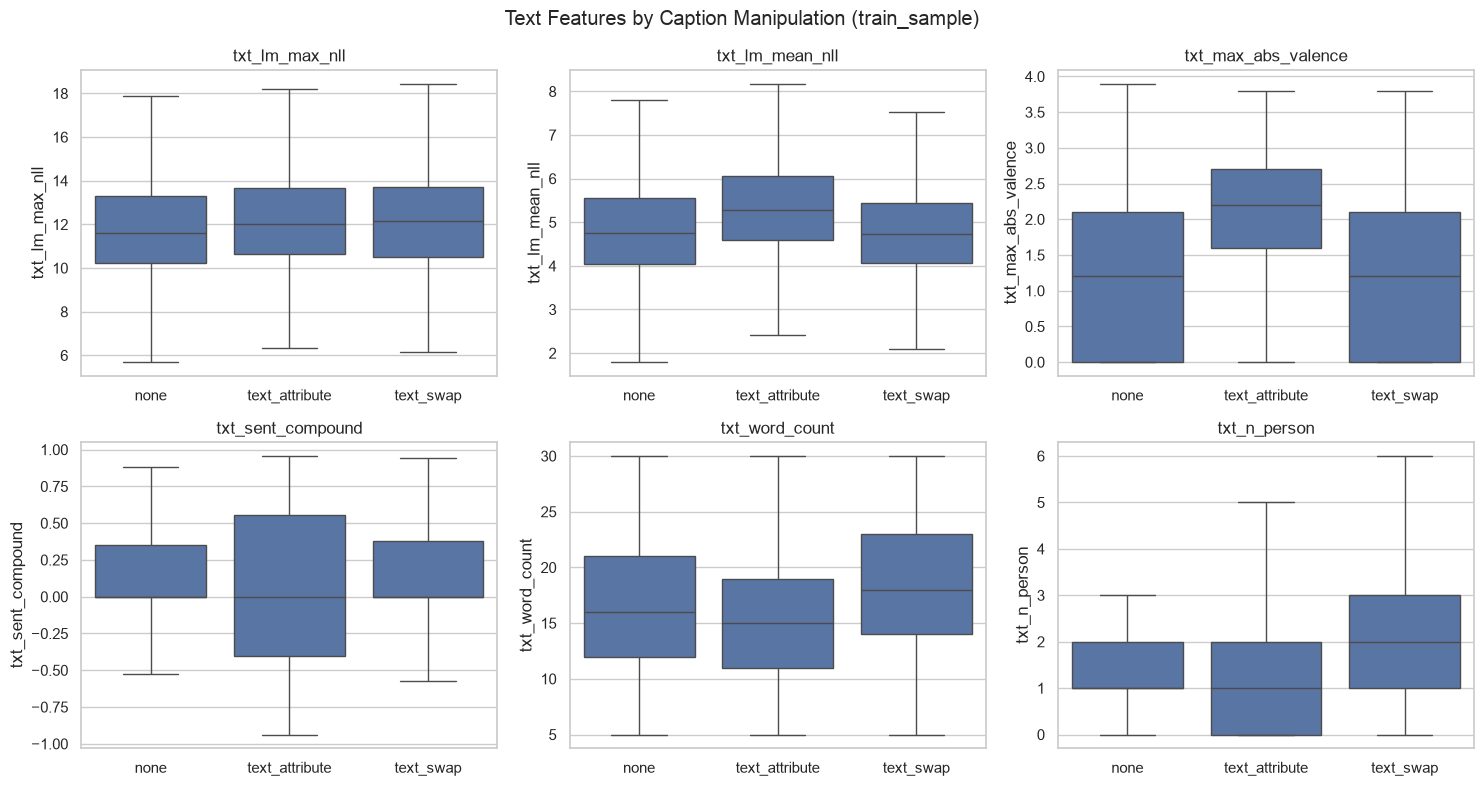

In [11]:
plot_cols = ["txt_lm_max_nll", "txt_lm_mean_nll", "txt_max_abs_valence", "txt_sent_compound", "txt_word_count", "txt_n_person"]
plot_df = data["train_sample"][["row_id", "text_manipulation"]].merge(text_features, on="row_id")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, plot_cols):
    sns.boxplot(data=plot_df, x="text_manipulation", y=col, order=["none", "text_attribute", "text_swap"],
                showfliers=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Text Features by Caption Manipulation (train_sample)")
plt.tight_layout()
plt.show()

In [12]:
save_features(text_features, "text")

data/features/text_train_sample.parquet  (49943, 22)
data/features/text_validation.parquet  (22126, 22)
data/features/text_test.parquet  (50705, 22)


# Summary

**Saved feature group:** `text` (`data/features/text_<split>.parquet`, joined on `row_id`): 21 `txt_*` features covering structure, named entities, VADER sentiment and GPT-2 surprise. They target text_attribute (sentiment flips, odd phrasing).

**What the features show (train_sample, single-feature AUC)**
- **text_attribute** is the most detectable caption edit: strongest word valence (AUC 0.72), VADER neutral share (0.26, i.e. 0.74 inverted) and GPT-2 mean surprise (0.63). Flipped words are more emotionally charged and make captions less fluent.
- **text_swap** is barely detectable from text alone (best: number of people mentioned, 0.69; length, 0.59). As expected, it needs image-caption consistency features (`05_clip_features`).

**Shortcut found and excluded** (`src/feature_sets.ARTIFACT_FEATURES`): caption length reflects how swapped captions were chosen.

**Adding features later:** add a new section that saves a new group with `save_features(df, "<group>")`, then join it in the modelling notebook on `row_id`.
